In [1]:
# Compare both models across different cluster counts
import pandas as pd
import numpy as np

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

X_scaled = pd.read_csv("Customer_Features_Scaled.csv")

evaluation_results = []

for k in range(2, 11):

    models = {
        "K-Means": KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        ),
        "Hierarchical": AgglomerativeClustering(
            n_clusters=k,
            linkage="ward"
        )
    }

    for model_name, model in models.items():

        labels = model.fit_predict(X_scaled)

        evaluation_results.append({
            "Model": model_name,
            "K": k,
            "Silhouette": silhouette_score(
                X_scaled,
                labels,
                sample_size=2000,
                random_state=42
            ),
            "Davies_Bouldin": davies_bouldin_score(
                X_scaled, labels
            ),
            "Calinski_Harabasz": calinski_harabasz_score(
                X_scaled, labels
            ),
            "Smallest_Cluster": int(
                pd.Series(labels).value_counts().min()
            ),
            "Largest_Cluster": int(
                pd.Series(labels).value_counts().max()
            )
        })

evaluation_df = pd.DataFrame(evaluation_results)

display(
    evaluation_df.round(4).sort_values(
        ["K", "Model"]
    )
)

,Model,K,Silhouette,Davies_Bouldin,Calinski_Harabasz,Smallest_Cluster,Largest_Cluster
1,Hierarchical,2,0.4772,1.1341,2878.7434,1324,3720
0,K-Means,2,0.5192,0.9344,3703.8627,1128,3916
3,Hierarchical,3,0.4834,0.9338,2547.2325,442,3720
2,K-Means,3,0.4122,1.0300,3177.0861,485,2565
5,Hierarchical,4,0.4865,0.8775,2453.9124,84,3720
4,K-Means,4,0.4639,0.8858,3327.1712,339,2413
7,Hierarchical,5,0.3663,0.9338,2641.3671,84,2268
6,K-Means,5,0.4610,0.8997,3187.2155,133,2307
9,Hierarchical,6,0.4428,0.8567,2669.9472,84,1452
8,K-Means,6,0.4709,0.8641,3184.4612,119,1824


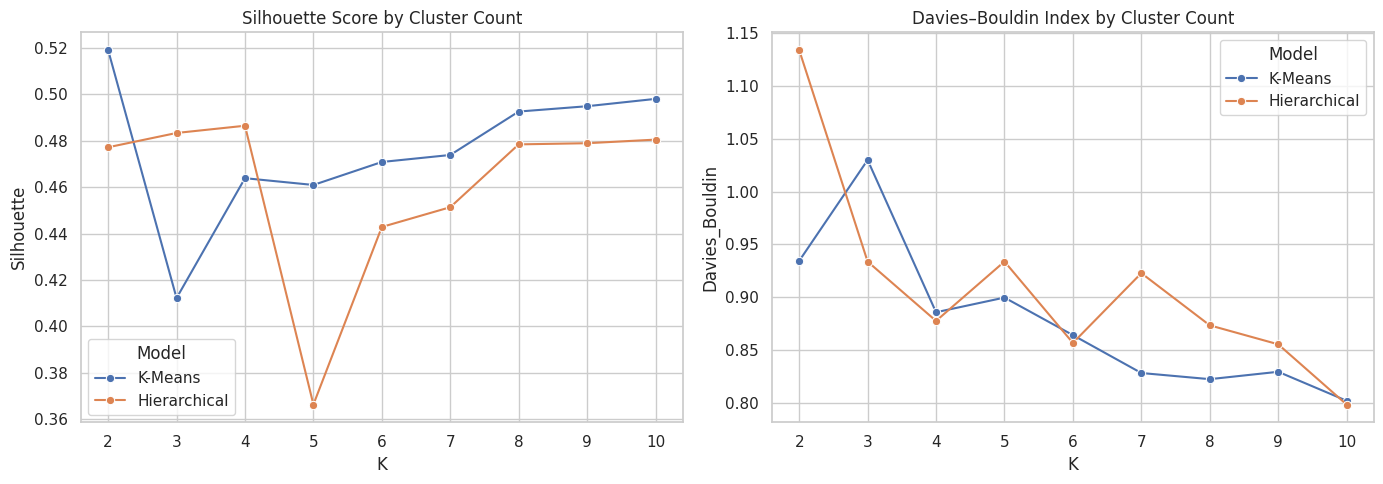

In [2]:
#Visualize the evaluation results
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(
    data=evaluation_df,
    x="K",
    y="Silhouette",
    hue="Model",
    marker="o",
    ax=axes[0]
)
axes[0].set_title("Silhouette Score by Cluster Count")

sns.lineplot(
    data=evaluation_df,
    x="K",
    y="Davies_Bouldin",
    hue="Model",
    marker="o",
    ax=axes[1]
)
axes[1].set_title("Davies–Bouldin Index by Cluster Count")

plt.tight_layout()
plt.show()

In [3]:
# Save the evaluation report
evaluation_df.to_csv(
    "Final_Model_Evaluation.csv",
    index=False
)

print("Model evaluation saved successfully.")
display(
    evaluation_df.sort_values(
        "Silhouette", ascending=False
    ).head(10).round(4)
)

Model evaluation saved successfully.


,Model,K,Silhouette,Davies_Bouldin,Calinski_Harabasz,Smallest_Cluster,Largest_Cluster
0,K-Means,2,0.5192,0.9344,3703.8627,1128,3916
16,K-Means,10,0.4981,0.8019,3183.7156,14,1451
14,K-Means,9,0.4949,0.8294,3178.2473,12,1778
12,K-Means,8,0.4926,0.8224,3103.3022,8,1778
5,Hierarchical,4,0.4865,0.8775,2453.9124,84,3720
3,Hierarchical,3,0.4834,0.9338,2547.2325,442,3720
17,Hierarchical,10,0.4805,0.7984,2823.1151,5,1452
15,Hierarchical,9,0.4790,0.8554,2738.3939,5,1452
13,Hierarchical,8,0.4785,0.8734,2699.8567,84,1452
1,Hierarchical,2,0.4772,1.1341,2878.7434,1324,3720
